In [10]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.model_selection import KFold, train_test_split
from sklearn.svm import SVC

In [11]:
SEED = 407

def add_bias(X):
    """Prepend the x0 = 1 column. Input (N, d); Output (N, d+1)."""
    return np.column_stack([np.ones(len(X)), X])

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def new_ax(xlabel, ylabel, title, logx=False, logy=False):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title)
    if logx: ax.set_xscale("log")
    if logy: ax.set_yscale("log")
    ax.grid(alpha=0.3)
    return fig, ax

E.2 Experiment: the Gaussian kernel

make_moons(n_samples=300, noise=0.3, random_state=407), 100 points held out as the test set, SVC with the RBF kernel 

$K(x,x') = \exp(-\gamma\|x-x'\|^2)$ 

and fixed C = 0.1. Errors are 0/1 errors (fraction misclassified).

In [12]:
X, y = make_moons(n_samples=300, noise=0.3, random_state=SEED)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=100, random_state=SEED)
print("train:", X_tr.shape, " test:", X_te.shape)

C = 0.1
gammas = [0.01, 0.1, 1, 10, 100, 1000]

def err01(model, X, y):
    return np.mean(model.predict(X) != y)

train: (200, 2)  test: (100, 2)


E.2(a) Ein, Etest and number of support vectors

In [13]:
models, rows = {}, []
for g in gammas:
    m = SVC(kernel="rbf", gamma=g, C=C).fit(X_tr, y_tr)
    models[g] = m
    rows.append({"gamma": g,
                 "Ein": err01(m, X_tr, y_tr),
                 "Etest": err01(m, X_te, y_te),
                 "# SV": int(m.n_support_.sum()),
                 "# SV with alpha = C (bounded)": int(np.sum(np.isclose(np.abs(m.dual_coef_), C)))})
gamma_df = pd.DataFrame(rows)
gamma_df.style.format({"Ein": "{:.3f}", "Etest": "{:.3f}"})

,gamma,Ein,Etest,# SV,# SV with alpha = C (bounded)
0,0.010000,0.485,0.530,194,194
1,0.100000,0.220,0.180,158,158
2,1.000000,0.135,0.140,136,126
3,10.000000,0.120,0.090,196,185
4,100.000000,0.485,0.530,199,185
5,1000.000000,0.485,0.530,200,104


E.2(b) Decision boundaries for γ ∈ {0.1, 10, 1000}

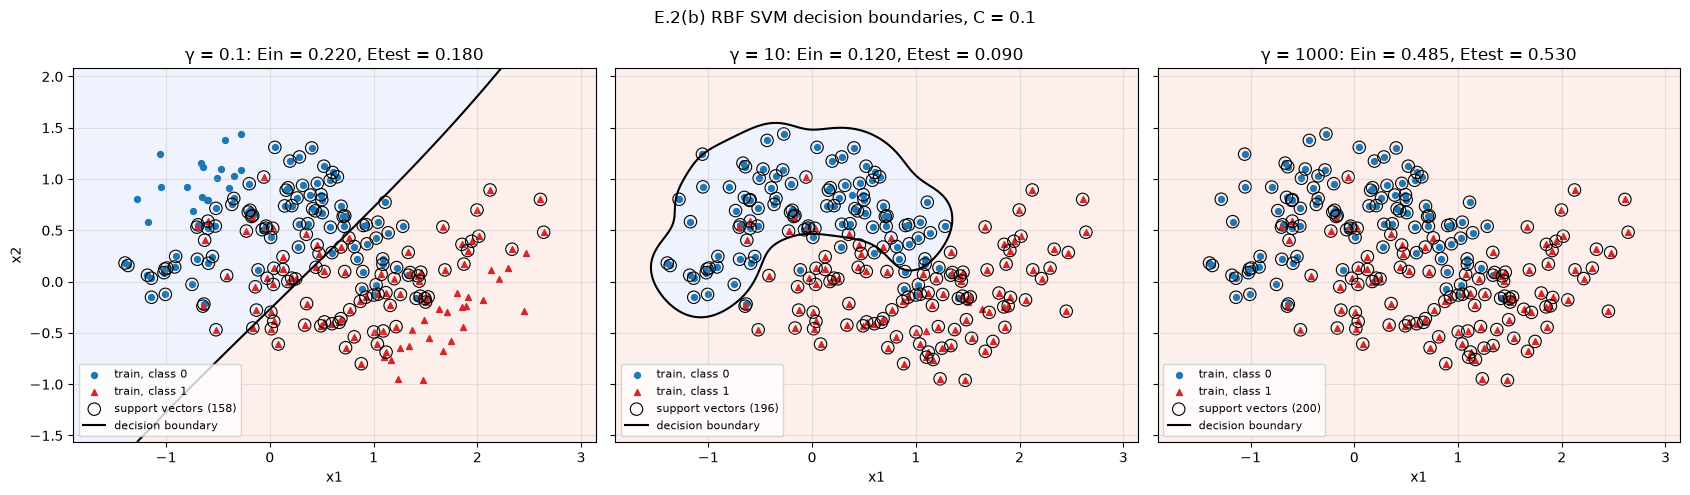

In [14]:
pad = 0.5
xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, 400),
                     np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, 400))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True)
for ax, g in zip(axes, [0.1, 10, 1000]):
    m = models[g]
    f = m.decision_function(grid).reshape(xx.shape)
    ax.contourf(xx, yy, f > 0, alpha=0.15, cmap="coolwarm")
    ax.contour(xx, yy, f, levels=[0], colors="k", linewidths=1.5)
    for cls, mk, c in [(0, "o", "C0"), (1, "^", "C3")]:
        ax.scatter(*X_tr[y_tr == cls].T, marker=mk, c=c, s=18, label=f"train, class {cls}")
    sv = m.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=80, facecolors="none", edgecolors="k",
               linewidths=0.8, label=f"support vectors ({len(sv)})")
    ax.plot([], [], "k-", label="decision boundary")
    ax.set_title(f"γ = {g}: Ein = {err01(m, X_tr, y_tr):.3f}, Etest = {err01(m, X_te, y_te):.3f}")
    ax.set_xlabel("x1"); ax.grid(alpha=0.3)
    ax.legend(loc="lower left", fontsize=8)
axes[0].set_ylabel("x2")
fig.suptitle("E.2(b) RBF SVM decision boundaries, C = 0.1")
fig.tight_layout(); fig.savefig("E2b_boundaries.png", dpi=150)

E.2(c) Selecting γ by 5-fold cross-validation on the 200 training points

In [15]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)

def cv_err01(g):
    errs = []
    for tr_idx, va_idx in kf.split(X_tr):
        m = SVC(kernel="rbf", gamma=g, C=C).fit(X_tr[tr_idx], y_tr[tr_idx])
        errs.append(err01(m, X_tr[va_idx], y_tr[va_idx]))
    return np.mean(errs)

gamma_df["Ecv (5-fold)"] = [cv_err01(g) for g in gammas]
g_cv = gamma_df.loc[gamma_df["Ecv (5-fold)"].idxmin(), "gamma"]
best_test = gamma_df["Etest"].min()
g_test_all = gamma_df.loc[np.isclose(gamma_df["Etest"], best_test), "gamma"].tolist()
print(f"CV selects gamma = {g_cv}")
print(f"Smallest Etest = {best_test:.3f}, reached by gamma in {g_test_all}")
print("Agree:", g_cv in g_test_all)
gamma_df[["gamma", "Ein", "Ecv (5-fold)", "Etest"]].style.format(
    {"Ein": "{:.3f}", "Ecv (5-fold)": "{:.3f}", "Etest": "{:.3f}"})

CV selects gamma = 1.0
Smallest Etest = 0.090, reached by gamma in [10.0]
Agree: False


,gamma,Ein,Ecv (5-fold),Etest
0,0.010000,0.485,0.495,0.530
1,0.100000,0.220,0.225,0.180
2,1.000000,0.135,0.135,0.140
3,10.000000,0.120,0.230,0.090
4,100.000000,0.485,0.505,0.530
5,1000.000000,0.485,0.520,0.530


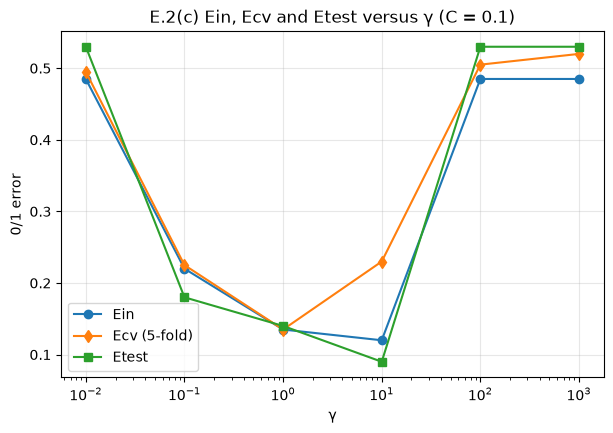

In [16]:
fig, ax = new_ax("γ", "0/1 error", "E.2(c) Ein, Ecv and Etest versus γ (C = 0.1)", logx=True)
ax.plot(gamma_df["gamma"], gamma_df["Ein"], "o-", label="Ein")
ax.plot(gamma_df["gamma"], gamma_df["Ecv (5-fold)"], "d-", label="Ecv (5-fold)")
ax.plot(gamma_df["gamma"], gamma_df["Etest"], "s-", label="Etest")
ax.legend(); fig.savefig("E2c_cv.png", dpi=150)

In [17]:
rows = []
for g in [1, 10, 100, 1000]:
    for C_big in [0.1, 1000]:
        m = SVC(kernel="rbf", gamma=g, C=C_big).fit(X_tr, y_tr)
        rows.append({"gamma": g, "C": C_big, "Ein": err01(m, X_tr, y_tr), "Etest": err01(m, X_te, y_te),
                     "# SV": int(m.n_support_.sum())})
pd.DataFrame(rows).style.format({"Ein": "{:.3f}", "Etest": "{:.3f}"})

,gamma,C,Ein,Etest,# SV
0,1,0.100000,0.135,0.140,136
1,1,1000.000000,0.105,0.090,59
2,10,0.100000,0.120,0.090,196
3,10,1000.000000,0.020,0.210,56
4,100,0.100000,0.485,0.530,199
5,100,1000.000000,0.000,0.240,184
6,1000,0.100000,0.485,0.530,200
7,1000,1000.000000,0.000,0.430,200


E.2(e) Numerical check: $\tilde K = pK + q$ with p = 3, q = 5

In [18]:
p, q = 3.0, 5.0
rows = []
for g in gammas:
    base = models[g]
    K_tr = p * rbf_kernel(X_tr, X_tr, gamma=g) + q
    K_te = p * rbf_kernel(X_te, X_tr, gamma=g) + q
    for name, C_tilde in [("C/p", C / p), ("pC", p * C)]:
        m = SVC(kernel="precomputed", C=C_tilde).fit(K_tr, y_tr)
        rows.append({
            "gamma": g,
            "C_tilde": name,
            "same test predictions": f"{np.mean(m.predict(K_te) == base.predict(X_te)):.0%}",
            "max |decision diff|": np.max(np.abs(m.decision_function(K_te) - base.decision_function(X_te))),
        })
check_df = pd.DataFrame(rows)
check_df.style.format({"max |decision diff|": "{:.2e}"})

,gamma,C_tilde,same test predictions,max |decision diff|
0,0.010000,C/p,100%,1.99e-09
1,0.010000,pC,47%,1.78e+00
2,0.100000,C/p,100%,1.19e-08
3,0.100000,pC,97%,1.06e+00
4,1.000000,C/p,100%,1.03e-07
5,1.000000,pC,94%,8.57e-01
6,10.000000,C/p,100%,2.97e-07
7,10.000000,pC,95%,8.79e-01
8,100.000000,C/p,100%,2.01e-04
9,100.000000,pC,62%,1.63e+00
